# Relatório de exploração e análise de vendas

**Projeto de prática com Python e Pandas**

Este relatório acompanha o caminho feito na análise de uma pequena base de vendas: primeiro foi conferida a estrutura dos dados, depois foram corrigidos problemas de organização, calculados indicadores e construídos gráficos para facilitar a leitura dos resultados.

A base contém registros de vendas de uma loja entre **1º e 10 de outubro de 2026**. O objetivo é praticar análise exploratória e transformar uma tabela simples em informações que ajudem a entender o comportamento das vendas.


## 1. O que queremos descobrir?

A análise foi organizada para responder a perguntas simples de negócio:

- Quanto a loja faturou no período e quantas unidades vendeu?
- Quais categorias e produtos geraram mais faturamento?
- Quais formas de pagamento aparecem com mais frequência e quais movimentaram mais dinheiro?
- Como o faturamento variou ao longo dos dias?
- Como ficou o faturamento por vendedor?
- A base tem dados ausentes, linhas duplicadas ou valores de faturamento inconsistentes?

## 2. Bibliotecas utilizadas

O Pandas será usado para carregar, limpar, organizar e resumir os dados. O Matplotlib será utilizado para montar os gráficos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

ARQUIVO = Path("loja_tratada.csv")

## 3. Primeira leitura: como o arquivo chegou?

Antes de analisar, vale observar como o CSV está estruturado.

In [2]:
bruta = pd.read_csv(ARQUIVO, sep=";", encoding="utf-8-sig")

print(f"Linhas e colunas antes da limpeza: {bruta.shape}")
print("\nNomes das colunas recebidas:")
print(bruta.columns.tolist())

display(bruta.head(4))

Linhas e colunas antes da limpeza: (21, 16)

Nomes das colunas recebidas:
['Data', 'Categoria', 'Produto', 'Quantidade', 'Formas de Pagamengo', 'PrecoUnitario', 'Faturamento', 'Vendedores', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15']


,Data,Categoria,Produto,Quantidade,Formas de Pagamengo,PrecoUnitario,Faturamento,Vendedores,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01/10/2026,Papelaria,Caderno,3.00,Pix,"R$ 12,50","R$ 37,50",Ana,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01/10/2026,Papelaria,Caneta,10.00,Cartao,"R$ 2,50","R$ 25,00",Bruno,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,02/10/2026,Acessorios,Mochila,1.00,Cartao,"R$ 89,90","R$ 89,90",Ana,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


o arquivo contém uma linha inteiramente vazia e colunas excedentes sem dados, causadas pelos separadores finais do CSV. Há também nomes de campos que precisam ser padronizados, como `Formas de Pagamengo`, e valores monetários que estão escritos como texto, por exemplo `R$ 12,50`.

## 4. Limpeza e organização dos dados

A limpeza será feita em etapas, para que fique claro o motivo de cada transformação:

1. remover linhas e colunas totalmente vazias;
2. padronizar os nomes das colunas;
3. converter data, quantidade e valores monetários para tipos adequados;
4. padronizar alguns rótulos para facilitar a leitura dos resultados;
5. calcular o faturamento a partir da quantidade e do preço unitário;
6. comparar o valor calculado com o faturamento informado no CSV.

In [3]:
# Remoção de linhas e colunas totalmente vazias
dados = bruta.dropna(axis=0, how="all").copy()
dados = dados.dropna(axis=1, how="all")

# Padronização dos nomes das colunas
dados = dados.rename(columns={
    "Formas de Pagamengo": "Forma_Pagamento",
    "PrecoUnitario": "Preco_Unitario",
    "Vendedores": "Vendedor",
    "Faturamento": "Faturamento_Informado"
})

# Retirada de espaços extras nos campos de texto
for coluna in ["Categoria", "Produto", "Forma_Pagamento", "Vendedor", "Data"]:
    dados[coluna] = dados[coluna].astype("string").str.strip()

# Conversão de valores no padrão brasileiro (ex.: "R$ 1.234,50") para número
def converter_moeda(valor):
    if pd.isna(valor):
        return np.nan
    if isinstance(valor, (int, float, np.number)):
        return float(valor)
    texto = str(valor).replace("R$", "").replace(" ", "")
    texto = texto.replace(".", "").replace(",", ".")
    return pd.to_numeric(texto, errors="coerce")

dados["Data"] = pd.to_datetime(dados["Data"], dayfirst=True, errors="coerce")
dados["Quantidade"] = pd.to_numeric(dados["Quantidade"], errors="coerce")
dados["Preco_Unitario"] = dados["Preco_Unitario"].map(converter_moeda)
dados["Faturamento_Informado"] = dados["Faturamento_Informado"].map(converter_moeda)

# Padronização de rótulos para apresentação
dados["Categoria"] = dados["Categoria"].replace({"Acessorios": "Acessórios"})
dados["Produto"] = dados["Produto"].replace({"Lapis": "Lápis"})
dados["Forma_Pagamento"] = dados["Forma_Pagamento"].replace({"Cartao": "Cartão"})

# Cálculo independente do faturamento
dados["Faturamento"] = dados["Quantidade"] * dados["Preco_Unitario"]
dados["Diferenca_Faturamento"] = dados["Faturamento_Informado"] - dados["Faturamento"]

# Organização final das colunas
ordem = [
    "Data", "Produto", "Categoria", "Quantidade", "Preco_Unitario",
    "Faturamento_Informado", "Faturamento", "Forma_Pagamento",
    "Vendedor", "Diferenca_Faturamento"
]
dados = dados[ordem]

print(f"Dimensão após a limpeza: {dados.shape[0]} linhas e {dados.shape[1]} colunas")
display(dados.head(8))

Dimensão após a limpeza: 20 linhas e 10 colunas


,Data,Produto,Categoria,Quantidade,Preco_Unitario,Faturamento_Informado,Faturamento,Forma_Pagamento,Vendedor,Diferenca_Faturamento
1,2026-10-01,Caderno,Papelaria,3.00,12.50,37.50,37.50,Pix,Ana,0.00
2,2026-10-01,Caneta,Papelaria,10.00,2.50,25.00,25.00,Cartão,Bruno,0.00
3,2026-10-02,Mochila,Acessórios,1.00,89.90,89.90,89.90,Cartão,Ana,0.00
4,2026-10-02,Lápis,Papelaria,8.00,1.50,12.00,12.00,Dinheiro,Carlos,0.00
5,2026-10-03,Caderno,Papelaria,2.00,12.50,25.00,25.00,Pix,Bruno,0.00
6,2026-10-03,Garrafa,Acessórios,2.00,25.00,50.00,50.00,Pix,Ana,0.00
7,2026-10-04,Caneta,Papelaria,15.00,2.50,37.50,37.50,Cartão,Carlos,0.00
8,2026-10-04,Mochila,Acessórios,1.00,79.90,79.90,79.90,Pix,Bruno,0.00


## 5. Conferência da qualidade da base

Agora verificamos os tipos de dados, a presença de valores ausentes, linhas duplicadas.

O faturamento calculado usa a regra:

**Faturamento = Quantidade × Preço unitário**

In [4]:
print("Tipos de dados:")
display(dados.dtypes.rename("Tipo").to_frame())

print("Valores ausentes por coluna:")
display(dados.isna().sum().rename("Valores ausentes").to_frame())

print(f"Linhas duplicadas completas: {dados.duplicated().sum()}")

diferencas = (dados["Diferenca_Faturamento"].abs() > 0.01).sum()
print(f"Registros com diferença entre faturamento informado e calculado: {diferencas}")

print("\nConferência dos valores monetários:")
display(dados[["Faturamento_Informado", "Faturamento", "Diferenca_Faturamento"]].head(8))

Tipos de dados:


,Tipo
Data,datetime64[us]
Produto,string
Categoria,string
Quantidade,float64
Preco_Unitario,float64
Faturamento_Informado,float64
Faturamento,float64
Forma_Pagamento,string
Vendedor,string
Diferenca_Faturamento,float64


Valores ausentes por coluna:


,Valores ausentes
Data,0
Produto,0
Categoria,0
Quantidade,0
Preco_Unitario,0
Faturamento_Informado,0
Faturamento,0
Forma_Pagamento,0
Vendedor,0
Diferenca_Faturamento,0


Linhas duplicadas completas: 0
Registros com diferença entre faturamento informado e calculado: 0

Conferência dos valores monetários:


,Faturamento_Informado,Faturamento,Diferenca_Faturamento
1,37.50,37.50,0.00
2,25.00,25.00,0.00
3,89.90,89.90,0.00
4,12.00,12.00,0.00
5,25.00,25.00,0.00
6,50.00,50.00,0.00
7,37.50,37.50,0.00
8,79.90,79.90,0.00


**Resultado da conferência:** os 20 registros têm valores preenchidos nos campos usados na análise, não há linhas totalmente duplicadas e o faturamento informado coincide com o cálculo de quantidade vezes preço unitário. Por isso, os gráficos usam o faturamento recalculado, mantendo o valor informado disponível para conferência.

## 6. Visão geral da base

Esta etapa resume as principais características da tabela antes de comparar categorias e produtos.

In [5]:
resumo_geral = pd.DataFrame({
    "Indicador": [
        "Quantidade de registros",
        "Data inicial",
        "Data final",
        "Produtos diferentes",
        "Categorias",
        "Vendedores",
        "Formas de pagamento"
    ],
    "Resultado": [
        len(dados),
        dados["Data"].min().strftime("%d/%m/%Y"),
        dados["Data"].max().strftime("%d/%m/%Y"),
        dados["Produto"].nunique(),
        dados["Categoria"].nunique(),
        dados["Vendedor"].nunique(),
        dados["Forma_Pagamento"].nunique()
    ]
})
display(resumo_geral)

print("Estatísticas das colunas numéricas:")
display(dados[["Quantidade", "Preco_Unitario", "Faturamento"]].describe().round(2))

,Indicador,Resultado
0,Quantidade de registros,20
1,Data inicial,01/10/2026
2,Data final,10/10/2026
3,Produtos diferentes,5
4,Categorias,2
5,Vendedores,3
6,Formas de pagamento,3


Estatísticas das colunas numéricas:


,Quantidade,Preco_Unitario,Faturamento
count,20.00,20.00,20.00
mean,5.50,25.28,46.25
std,5.38,31.88,40.12
min,1.00,1.50,10.50
25%,1.75,2.50,21.38
50%,3.00,12.50,33.75
75%,8.25,25.00,56.25
max,20.00,89.90,179.80


## 7. Indicadores principais

Os indicadores abaixo dão uma visão rápida do período analisado. “Registro” significa uma linha da base; a tabela não permite afirmar, por si só, que cada linha representa uma compra única de um cliente.

In [6]:
faturamento_total = dados["Faturamento"].sum()
unidades_vendidas = dados["Quantidade"].sum()
faturamento_medio_registro = dados["Faturamento"].mean()
produto_top_faturamento = dados.groupby("Produto")["Faturamento"].sum().idxmax()
valor_top_produto = dados.groupby("Produto")["Faturamento"].sum().max()
categoria_top = dados.groupby("Categoria")["Faturamento"].sum().idxmax()
valor_categoria_top = dados.groupby("Categoria")["Faturamento"].sum().max()
dia_top = dados.groupby("Data")["Faturamento"].sum().idxmax()
valor_dia_top = dados.groupby("Data")["Faturamento"].sum().max()

indicadores = pd.DataFrame({
    "Indicador": [
        "Faturamento total",
        "Unidades vendidas",
        "Faturamento médio por registro",
        "Produto com maior faturamento",
        "Categoria com maior faturamento",
        "Dia com maior faturamento"
    ],
    "Resultado": [
        f"R$ {faturamento_total:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."),
        f"{unidades_vendidas:.0f}",
        f"R$ {faturamento_medio_registro:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."),
        f"{produto_top_faturamento} — R$ {valor_top_produto:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."),
        f"{categoria_top} — R$ {valor_categoria_top:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."),
        f"{dia_top.strftime('%d/%m/%Y')} — R$ {valor_dia_top:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    ]
})
display(indicadores)

,Indicador,Resultado
0,Faturamento total,"R$ 925,00"
1,Unidades vendidas,110
2,Faturamento médio por registro,"R$ 46,25"
3,Produto com maior faturamento,"Mochila — R$ 429,50"
4,Categoria com maior faturamento,"Acessórios — R$ 629,50"
5,Dia com maior faturamento,"07/10/2026 — R$ 204,80"


## 8. Exploração por produto

Nesta parte, comparamos faturamento e volume de unidades. É importante olhar os dois indicadores juntos: vender muitas unidades não significa necessariamente gerar o maior faturamento, pois os preços são diferentes.

In [7]:
por_produto = (
    dados.groupby("Produto", as_index=True)
    .agg(
        Unidades=("Quantidade", "sum"),
        Registros=("Produto", "count"),
        Faturamento=("Faturamento", "sum")
    )
    .sort_values("Faturamento", ascending=False)
)
display(por_produto.style.format({
    "Unidades": "{:.0f}",
    "Registros": "{:.0f}",
    "Faturamento": "R$ {:,.2f}"
}))

,Unidades,Registros,Faturamento
Produto,,,
Mochila,5,4,R$ 429.50
Garrafa,8,4,R$ 200.00
Caderno,10,4,R$ 125.00
Caneta,40,4,R$ 100.00
Lápis,47,4,R$ 70.50


### Gráfico 1 — Faturamento por produto

O gráfico ordena os produtos pelo faturamento total. Assim, fica fácil visualizar quais itens tiveram maior contribuição financeira no período.

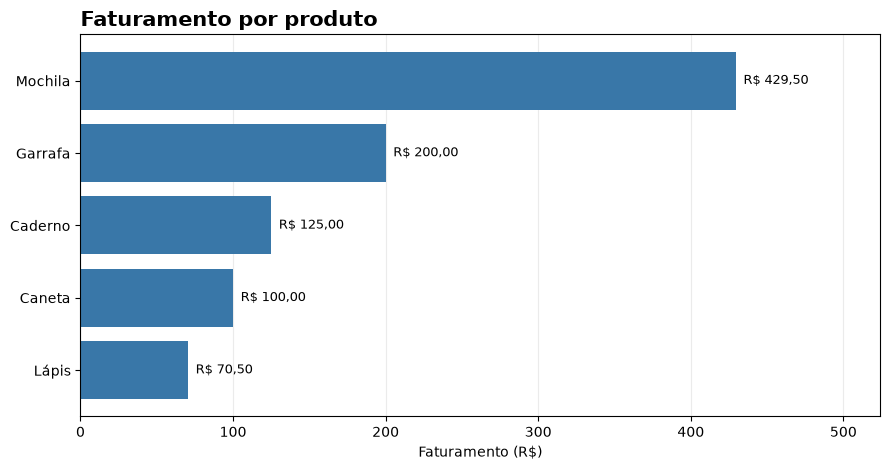

In [9]:
faturamento_produto = dados.groupby("Produto")["Faturamento"].sum().sort_values()

fig, ax = plt.subplots(figsize=(9, 4.8))
barras = ax.barh(faturamento_produto.index, faturamento_produto.values, color="#3977A8")
ax.set_title("Faturamento por produto", loc="left", fontsize=15, weight="bold")
ax.set_xlabel("Faturamento (R$)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
for barra, valor in zip(barras, faturamento_produto.values):
    ax.text(valor + 5, barra.get_y() + barra.get_height()/2, f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."), va="center", fontsize=9)
ax.set_xlim(0, faturamento_produto.max() * 1.22)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** a mochila concentra o maior faturamento entre os produtos, enquanto o lápis, apesar de apresentar a maior quantidade de unidades vendidas, gera o menor faturamento total entre os cinco itens. A diferença reforça a importância de analisar valor e quantidade em conjunto.

### Gráfico 2  Quantidade vendida por produto

Este segundo gráfico muda a pergunta: em vez de dinheiro, compara o número de unidades vendidas.

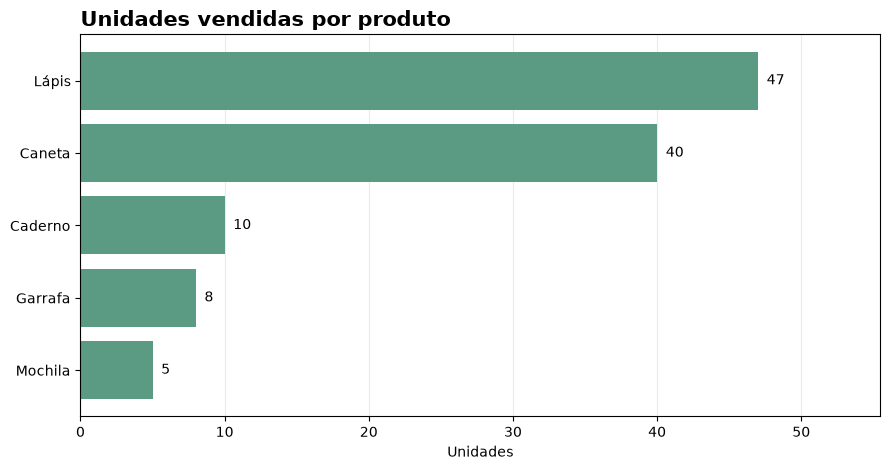

In [8]:
quantidade_produto = dados.groupby("Produto")["Quantidade"].sum().sort_values()

fig, ax = plt.subplots(figsize=(9, 4.8))
barras = ax.barh(quantidade_produto.index, quantidade_produto.values, color="#5B9B83")
ax.set_title("Unidades vendidas por produto", loc="left", fontsize=15, weight="bold")
ax.set_xlabel("Unidades")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
for barra, valor in zip(barras, quantidade_produto.values):
    ax.text(valor + 0.6, barra.get_y() + barra.get_height()/2, f"{valor:.0f}", va="center", fontsize=10)
ax.set_xlim(0, quantidade_produto.max() * 1.18)
plt.tight_layout()
plt.show()

## 9. Exploração por categoria

A comparação por categoria ajuda a entender de qual grupo de produtos veio a maior parte do faturamento. O resultado depende tanto do preço dos itens quanto das quantidades vendidas.

In [11]:
por_categoria = (
    dados.groupby("Categoria")
    .agg(
        Unidades=("Quantidade", "sum"),
        Registros=("Produto", "count"),
        Faturamento=("Faturamento", "sum")
    )
    .sort_values("Faturamento", ascending=False)
)
display(por_categoria.style.format({
    "Unidades": "{:.0f}",
    "Registros": "{:.0f}",
    "Faturamento": "R$ {:,.2f}"
}))

,Unidades,Registros,Faturamento
Categoria,,,
Acessórios,13,8,R$ 629.50
Papelaria,97,12,R$ 295.50


### Gráfico 3 — Faturamento por categoria

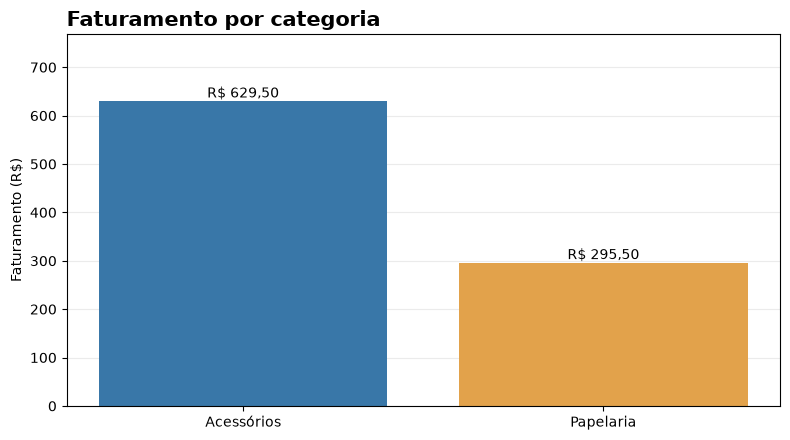

In [12]:
faturamento_categoria = dados.groupby("Categoria")["Faturamento"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(faturamento_categoria.index, faturamento_categoria.values, color=["#3977A8", "#E2A24B"][:len(faturamento_categoria)])
ax.set_title("Faturamento por categoria", loc="left", fontsize=15, weight="bold")
ax.set_ylabel("Faturamento (R$)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
for barra, valor in zip(barras, faturamento_categoria.values):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 8, f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."), ha="center", fontsize=10)
ax.set_ylim(0, faturamento_categoria.max() * 1.22)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** acessórios respondem pela maior parcela do faturamento, embora a papelaria tenha concentrado mais registros de venda e mais unidades comercializadas. Isso acontece porque os produtos de acessórios têm preços unitários mais altos nesta base.

## 10. Exploração por forma de pagamento

A contagem de registros e o faturamento por forma de pagamento não medem a mesma coisa. Por isso, a análise apresenta os dois indicadores separadamente.

In [13]:
por_pagamento = (
    dados.groupby("Forma_Pagamento")
    .agg(
        Registros=("Produto", "count"),
        Faturamento=("Faturamento", "sum")
    )
    .sort_values("Faturamento", ascending=False)
)
display(por_pagamento.style.format({
    "Registros": "{:.0f}",
    "Faturamento": "R$ {:,.2f}"
}))

,Registros,Faturamento
Forma_Pagamento,,
Cartão,8,R$ 519.70
Pix,8,R$ 339.80
Dinheiro,4,R$ 65.50


### Gráfico 4 Faturamento por forma de pagamento

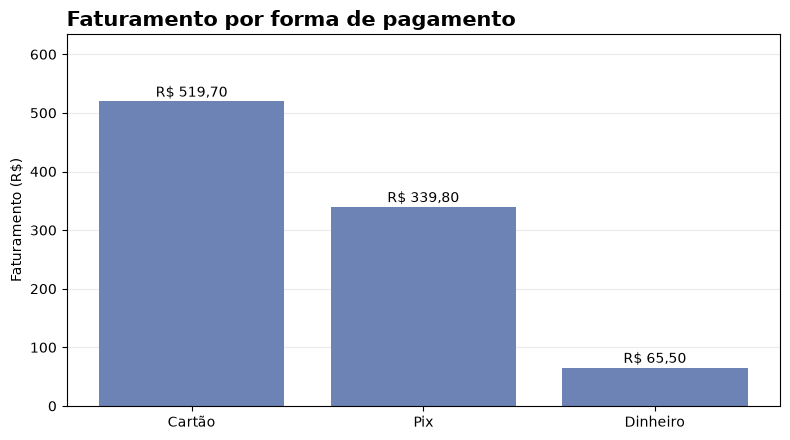

In [14]:
faturamento_pagamento = dados.groupby("Forma_Pagamento")["Faturamento"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(faturamento_pagamento.index, faturamento_pagamento.values, color="#6D83B5")
ax.set_title("Faturamento por forma de pagamento", loc="left", fontsize=15, weight="bold")
ax.set_ylabel("Faturamento (R$)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
for barra, valor in zip(barras, faturamento_pagamento.values):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 8, f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."), ha="center", fontsize=10)
ax.set_ylim(0, faturamento_pagamento.max() * 1.22)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** cartão e Pix aparecem em oito registros cada, mas o cartão reúne o maior faturamento total. O dinheiro aparece em quatro registros e movimenta o menor valor entre as três formas de pagamento.

## 11. Exploração por vendedor

O agrupamento por vendedor mostra o valor total associado aos registros de cada pessoa. Ele não informa, sozinho, produtividade, jornada trabalhada ou dificuldade das vendas; portanto, serve como comparação descritiva da base.

In [15]:
por_vendedor = (
    dados.groupby("Vendedor")
    .agg(
        Registros=("Produto", "count"),
        Unidades=("Quantidade", "sum"),
        Faturamento=("Faturamento", "sum")
    )
    .sort_values("Faturamento", ascending=False)
)
display(por_vendedor.style.format({
    "Registros": "{:.0f}",
    "Unidades": "{:.0f}",
    "Faturamento": "R$ {:,.2f}"
}))

,Registros,Unidades,Faturamento
Vendedor,,,
Ana,8,33,R$ 372.80
Carlos,6,36,R$ 327.30
Bruno,6,41,R$ 224.90


### Gráfico 5 Faturamento por vendedor

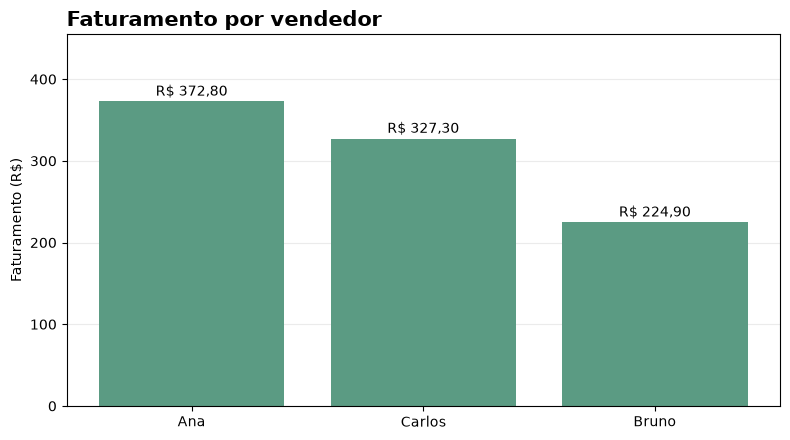

In [16]:
faturamento_vendedor = dados.groupby("Vendedor")["Faturamento"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(faturamento_vendedor.index, faturamento_vendedor.values, color="#5B9B83")
ax.set_title("Faturamento por vendedor", loc="left", fontsize=15, weight="bold")
ax.set_ylabel("Faturamento (R$)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
for barra, valor in zip(barras, faturamento_vendedor.values):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 7, f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."), ha="center", fontsize=10)
ax.set_ylim(0, faturamento_vendedor.max() * 1.22)
plt.tight_layout()
plt.show()

## 12. Evolução diária do faturamento

O gráfico diário ajuda a perceber variações no período. Como a base cobre apenas dez dias, a leitura descreve este recorte e não deve ser tratada como uma tendência de longo prazo.

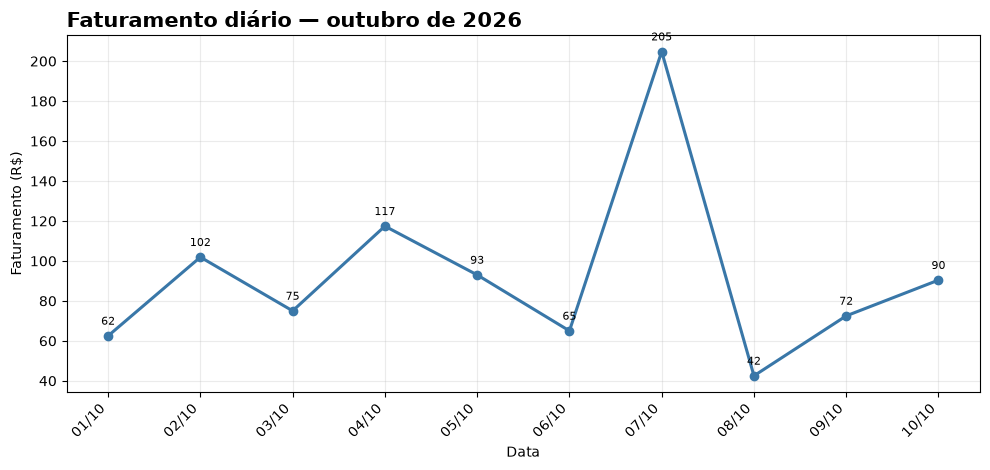

In [17]:
faturamento_diario = dados.groupby("Data")["Faturamento"].sum().sort_index()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(faturamento_diario.index, faturamento_diario.values, marker="o", linewidth=2.2, color="#3977A8")
ax.set_title("Faturamento diário — outubro de 2026", loc="left", fontsize=15, weight="bold")
ax.set_xlabel("Data")
ax.set_ylabel("Faturamento (R$)")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.set_xticks(faturamento_diario.index)
ax.set_xticklabels([data.strftime("%d/%m") for data in faturamento_diario.index], rotation=45, ha="right")
for data, valor in faturamento_diario.items():
    ax.annotate(f"{valor:.0f}", (data, valor), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** o maior faturamento diário foi registrado em **07/10/2026**, com R$ 204,80. O menor foi em **08/10/2026**, com R$ 42,50. O recorte mostra oscilações entre os dias, então não é suficiente para afirmar que o faturamento está crescendo ou caindo de forma contínua.

## 13. Resumo dos achados

Com base nos cálculos e gráficos acima, os principais pontos são:

- O faturamento total foi de **R$ 925,00**, com **110 unidades** vendidas em 20 registros.
- **Acessórios** somaram R$ 629,50, acima dos R$ 295,50 de papelaria.
- **Mochila** foi o produto que mais faturou (R$ 429,50); **lápis** teve o maior volume (47 unidades).
- **Cartão** teve o maior faturamento entre os meios de pagamento (R$ 519,70). Pix e cartão aparecem oito vezes cada.
- **Ana** teve o maior faturamento agregado entre os vendedores (R$ 372,80).
- O maior faturamento diário ocorreu em 07/10/2026 (R$ 204,80).
- O faturamento calculado pela multiplicação entre quantidade e preço unitário coincide com o valor informado no CSV nos 20 registros.

Esses achados descrevem somente os dados disponíveis. Não há informações sobre custos, margem de lucro, estoque, clientes ou metas; por isso, não é possível concluir quais produtos são mais lucrativos ou explicar as causas das variações.


### Limitações conhecidas

A base é pequena e cobre apenas dez dias. Cada linha foi tratada como um registro de venda, mas não há um identificador de pedido ou cliente. Portanto, as conclusões são descritivas e não permitem avaliar lucro, comportamento de clientes ou desempenho além do período observado.